In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pylab as plt
from tqdm import tqdm

# PB

### Reduce sqanti output

In [13]:
sqanti = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/at9900_liftoff_sqanti/at9900-pb-vs-liftoff_classification.txt", sep="\t")
sub = sqanti[["isoform","exons","length","structural_category","associated_gene","associated_transcript","subcategory","ORF_seq"]]
sub["gene"] = sub["isoform"].str.split(".").str[0] + sub["isoform"].str.split(".").str[1]

/tmp/ipykernel_28926/2622539834.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sub["gene"] = sub["isoform"].str.split(".").str[0] + sub["isoform"].str.split(".").str[1]


# Transdecoder ORFs

In [14]:
header=["seqid","source","type","start","end","score","strand","phase","attributes"]
trans = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/at9900_transdecoder/at9900_transcripts.fasta.transdecoder.genome.gff3", sep="\t", names=header)
mRNA=trans[trans["type"] == "mRNA"]
mRNA['isoform'] = mRNA['attributes'].str.split(";").str[0].str.split("=").str[1].str.split(".p").str[0]

/tmp/ipykernel_28926/20682166.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mRNA['isoform'] = mRNA['attributes'].str.split(";").str[0].str.split("=").str[1].str.split(".p").str[0]


### Sqanti + Transdecoder

In [15]:
merged_left = pd.merge(left=sub, right=mRNA['isoform'].value_counts().reset_index().rename({'index':"isoform",'isoform':"n_ORFS"},axis='columns'), how='left', left_on='isoform', right_on='isoform')

### Read Support

In [20]:
reads=pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/at9900.collapsed.pb.v2.abundance.txt",sep="\t", skiprows=3)
r_sub = reads[["pbid","fl_assoc"]]
r_sub.columns = ["isoform", "isoform_reads"]

In [34]:
r_sub["gene"]=r_sub["isoform"].str.split(".").str[0]+r_sub["isoform"].str.split(".").str[1]
#r_sub["gene_reads"] = pd.Series([], dtype=object)
r_sub.loc["gene_reads"] = int(0)
for i in tqdm(r_sub.groupby("gene")):
    #print(i[1]["isoform_reads"].sum())
    r_sub.loc[r_sub["gene"]==i[0], "gene_reads"] = i[1]["isoform_reads"].sum()
merged_all["gene_reads"]= merged_all["gene_reads"].astype("int")

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 16858/16858 [09:11<00:00, 30.55it/s]


### Sqanti + Transdecoder + Read Support

In [43]:
merged_all = pd.merge(left=merged_left, right=r_sub[["isoform","isoform_reads","gene_reads"]], how='left', left_on='isoform', right_on='isoform')

# Ref Genes

In [7]:
busco = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/analysis/sqanti/ref_genes/busco_Araport11_20221221.txt", header=None)
house = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/analysis/sqanti/ref_genes/arat_housekeeping.txt", header=None)
nlr = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/analysis/sqanti/ref_genes/nlrs_in_orthogroups_20221221.txt", header=None)

In [8]:
busco["type"] = "busco"
house["type"] = "housekeeping"
nlr["type"] = "nlr"
gene_type = pd.concat([busco,house,nlr])
gene_type.columns = ["ref_isoform","type"]
gene_type = gene_type.groupby("ref_isoform")["type"].apply(', '.join).reset_index()

In [9]:
gene_type["ref_gene"] = gene_type["ref_isoform"].str.split(".").str[0]
gene_type.loc[gene_type["type"] == "busco, nlr"] = "nlr"
gene_type.loc[gene_type["type"] == "housekeeping, nlr"] = "nlr"
gene_type.loc[gene_type["type"] == "busco, housekeeping"] = "housekeeping"
print(gene_type["type"].value_counts())

busco           4483
housekeeping     704
nlr              252
Name: type, dtype: int64


### RELATE VIA ISOFORM, NOT GENE HERE

In [10]:
iso_ref = pd.merge(left=merged_all, right=gene_type, how='left', left_on='associated_transcript', right_on='ref_isoform')
print(iso_ref["type"].value_counts())
iso_nlr = iso_ref.loc[iso_ref["type"] == "nlr"]
iso_busco = iso_ref.loc[iso_ref["type"] == "busco"]
iso_house = iso_ref.loc[iso_ref["type"] == "housekeeping"]
iso_all = pd.concat([iso_nlr,iso_busco,iso_house])

busco           28165
housekeeping     1801
nlr               549
Name: type, dtype: int64


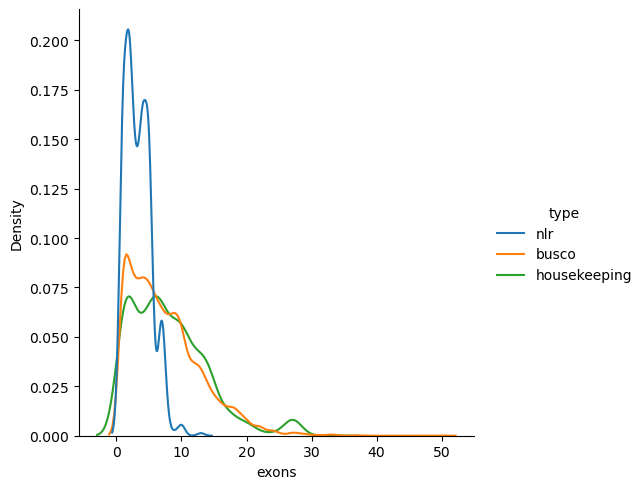

In [11]:
sns.displot(iso_all, x="exons", hue = "type", kind="kde",common_norm=False)

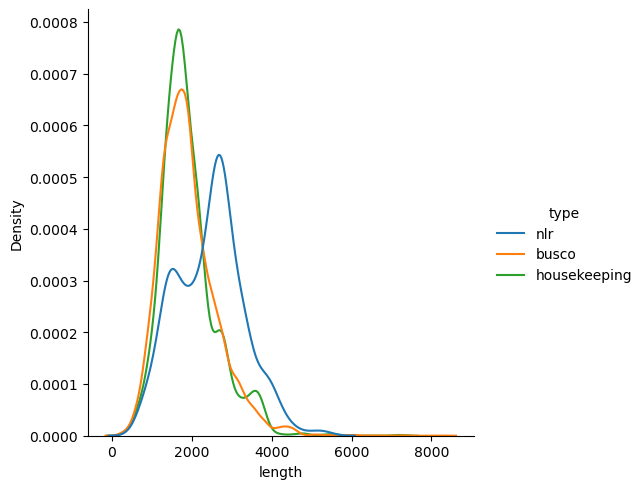

In [12]:
sns.displot(iso_all, x="length", hue = "type", kind="kde",common_norm=False)

([0, 1, 2, 3, 4, 5, 6, 7, 8],
 [Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, '')])

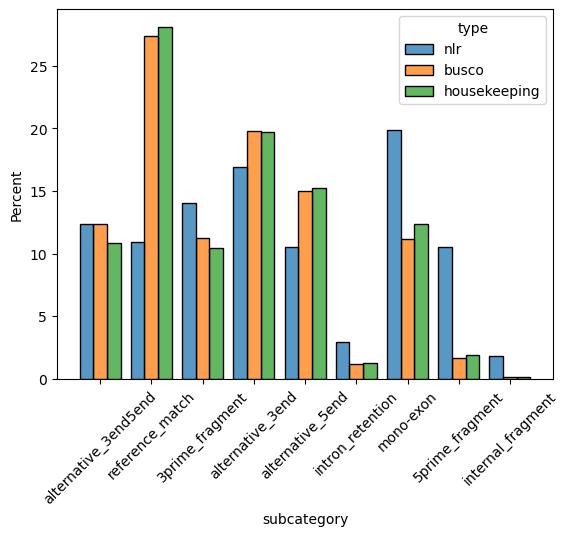

In [13]:
sns.histplot(iso_all, x="subcategory", hue = "type", multiple= "dodge", stat="percent", common_norm=False, shrink = 0.8)
plt.xticks(rotation=45)

### RELATE VIA GENE, NOT ISOFORM HERE

In [14]:
gene_ref = pd.merge(left=merged_all, right=gene_type, how='left', left_on='associated_gene', right_on='ref_gene')
print(gene_ref["type"].value_counts())
gene_nlr = gene_ref.loc[gene_ref["type"] == "nlr"]
gene_busco = gene_ref.loc[gene_ref["type"] == "busco"]
gene_house = gene_ref.loc[gene_ref["type"] == "housekeeping"]
gene_all = pd.concat([gene_nlr,gene_busco,gene_house])

busco           62598
housekeeping     5321
nlr              1740
Name: type, dtype: int64


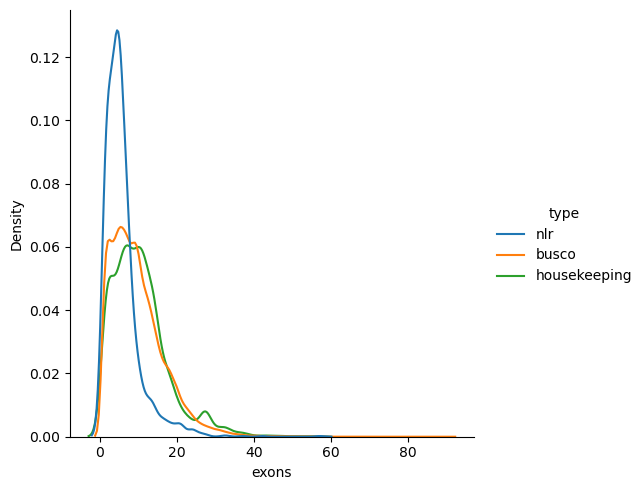

In [15]:
sns.displot(gene_all, x="exons", hue = "type", kind="kde",common_norm=False)

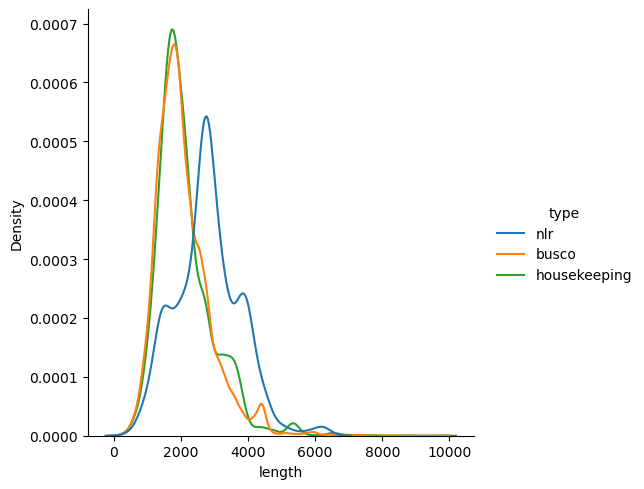

In [16]:
sns.displot(gene_all, x="length", hue = "type", kind="kde",common_norm=False)

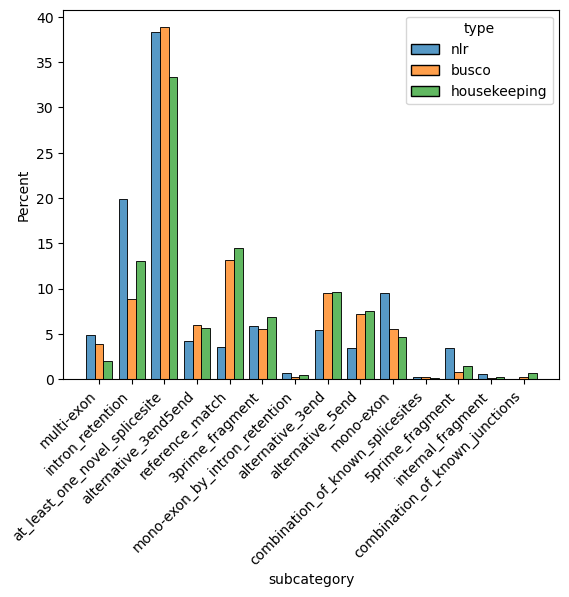

In [17]:
sns.histplot(gene_all, x="subcategory", hue = "type", multiple= "dodge", stat="percent", common_norm=False, shrink = 0.8)
plt.xticks(rotation=45, horizontalalignment='right')
plt.savefig("pb_liftoff_sqanti.png", bbox_inches='tight')

## All at oncevalue_counts

In [ ]:
### Liftoff

In [ ]:
accessions= ['at6923','at6929','at7143','at8285','at9104','at9336','at9503','at9578','at9744','at9762','at9806','at9830','at9847','at9852','at9879','at9883','at9900','col0']


pb_liftoff_df = pd.DataFrame()

for acc in accessions:
    sqanti = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/{}_liftoff_sqanti/{}-pb-vs-liftoff_classification.txt".format(acc,acc), sep="\t")
    sub = sqanti[["isoform","exons","length","structural_category","associated_gene","associated_transcript","subcategory","ORF_seq"]]
    sub["gene"] = sub["isoform"].str.split(".").str[0]

    header=["seqid","source","type","start","end","score","strand","phase","attributes"]
    trans = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/{}_transdecoder/{}_transcripts.fasta.transdecoder.genome.gff3".format(acc,acc), sep="\t", names=header)
    mRNA=trans[trans["type"] == "mRNA"]
    mRNA['isoform'] = mRNA['attributes'].str.split(";").str[0].str.split("=").str[1].str.split(".p").str[0]
    
    merged_left = pd.merge(left=sub, right=mRNA['isoform'].value_counts().reset_index().rename({'index':"isoform",'isoform':"n_ORFS"},axis='columns'), how='left', left_on='isoform', right_on='isoform')
    
    reads = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/{}.collapsed.pb.v2_read_support.txt".format(acc), sep="\t")
    r_sub = reads[["merge_trans_id","trans_read_count","gene_read_count"]]
    r_sub.columns = ["isoform", "isoform_reads", "gene_reads"]

    merged_all = pd.merge(left=merged_left, right=r_sub, how='left', left_on='isoform', right_on='isoform')
    merged_all['accession'] = acc
    
    pb_liftoff_df = pd.concat([pb_liftoff_df, merged_all])
print(pb_liftoff_df)

In [ ]:
pb_liftoff_df = pb_liftoff_df[["gene","isoform","accession","associated_gene","associated_transcript","exons","isoform_reads","gene_reads","structural_category","subcategory","n_ORFS","ORF_seq"]]
pb_liftoff_df.columns = ["gene","isoform","accession","associated_gene","associated_transcript","exons","isoform_read_support","gene_read_support","structural_category","subcategory","n_transdecoder_ORFs","Sqanti_ORF_seq"]
pb_liftoff_df.to_csv("./pb_liftoff_sqanti.tsv", sep="\t")

### augustus

In [ ]:
accessions= ['at6923','at6929','at7143','at8285','at9104','at9336','at9503','at9578','at9744','at9762','at9806','at9830','at9847','at9852','at9879','at9883','at9900','col0']


pb_augustus_df = pd.DataFrame()

for acc in accessions:
    sqanti = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/{}_augustus_sqanti/{}-pb-vs-augustus_classification.txt".format(acc,acc), sep="\t")
    sub = sqanti[["isoform","exons","length","structural_category","associated_gene","associated_transcript","subcategory","ORF_seq"]]
    sub["gene"] = sub["isoform"].str.split(".").str[0]

    header=["seqid","source","type","start","end","score","strand","phase","attributes"]
    trans = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/{}_transdecoder/{}_transcripts.fasta.transdecoder.genome.gff3".format(acc,acc), sep="\t", names=header)
    mRNA=trans[trans["type"] == "mRNA"]
    mRNA['isoform'] = mRNA['attributes'].str.split(";").str[0].str.split("=").str[1].str.split(".p").str[0]
    
    merged_left = pd.merge(left=sub, right=mRNA['isoform'].value_counts().reset_index().rename({'index':"isoform",'isoform':"n_ORFS"},axis='columns'), how='left', left_on='isoform', right_on='isoform')
    
    reads = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/{}.collapsed.pb.v2_read_support.txt".format(acc), sep="\t")
    r_sub = reads[["merge_trans_id","trans_read_count","gene_read_count"]]
    r_sub.columns = ["isoform", "isoform_reads", "gene_reads"]

    merged_all = pd.merge(left=merged_left, right=r_sub, how='left', left_on='isoform', right_on='isoform')
    merged_all['accession'] = acc
    
    pb_augustus_df = pd.concat([pb_augustus_df, merged_all])
print(pb_augustus_df)

In [ ]:
pb_augustus_df = pb_augustus_df[["gene","isoform","accession","associated_gene","associated_transcript","exons","length","isoform_reads","gene_reads","structural_category","subcategory","n_ORFS","ORF_seq"]]
pb_augustus_df.columns = ["gene","isoform","accession","associated_gene","associated_transcript","exons","length","isoform_read_support","gene_read_support","structural_category","subcategory","n_transdecoder_ORFs","Sqanti_ORF_seq"]
pb_augustus_df.to_csv("./pb_augustus_sqanti.tsv", sep="\t")

### Generate list of subdataframes

In [57]:
list(sub.groupby("gene"))

[('G1',
    isoform  exons structural_category associated_gene associated_transcript  \
  0    G1.1    6.0   full-splice_match       AT1G01010           AT1G01010.1   
  1    G1.2    6.0   full-splice_match       AT1G01010           AT1G01010.1   
  
                                               ORF_seq gene  
  0  MEDQVGFGFRPNDEELVGHYLRNKIEGNTSRDVEVAISEVNICSYD...   G1  
  1  MEDQVGFGFRPNDEELVGHYLRNKIEGNTSRDVEVAISEVNICSYD...   G1  ),
 ('G10',
    isoform  exons   structural_category associated_gene associated_transcript  \
  2   G10.1    5.0     full-splice_match       AT1G01110           AT1G01110.2   
  3   G10.2    5.0  novel_not_in_catalog       AT1G01110                 novel   
  
                                               ORF_seq gene  
  2  MGKKNGSSSWLTAVKRAFRSPTKKDHSNDVEEDEEKKREKRRWFRK...  G10  
  3  MGKKNGSSSWLTAVKRAFRSPTKKDHSNDVEEDEEKREKRRWFRKP...  G10  ),
 ('G100',
      isoform  exons      structural_category      associated_gene  \
  4    G100.1    8.0        full-sp

In [38]:
test= sub.set_index("gene").sort_index().stack()

gene                        
G1     isoform                                                               G1.1
       exons                                                                    6
       structural_category                                      full-splice_match
       associated_gene                                                  AT1G01010
       associated_transcript                                          AT1G01010.1
                                                      ...                        
G9999  exons                                                                    7
       structural_category                                      full-splice_match
       associated_gene                                                  AT3G60210
       associated_transcript                                          AT3G60210.1
       ORF_seq                  MASSFITVPKPFLSFPIKTNAPTLPQQTLLGIRRNSFRINAVSTKW...
Length: 1178291, dtype: object
